## A1 — Environment and reproducibility
Python and scikit-learn versions, imports, and the two fixed seeds.

In [1]:
import sys, platform
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
    precision_score, recall_score, f1_score, matthews_corrcoef,
    balanced_accuracy_score, make_scorer, classification_report
)
from scipy.stats import binomtest, t
SEED_SPLIT = 42
SEED_FOREST = 0
print("Python      :", platform.python_version())
print("scikit-learn:", sklearn.__version__)
print("Seeds        : split =", SEED_SPLIT, "| forest =",  SEED_FOREST)

Python      : 3.12.3
scikit-learn: 1.8.0
Seeds        : split = 42 | forest = 0


## A2 — Data loading and schema
Source, dimensions, and the target recoding that makes **malignant the positive class**.

In [2]:
data = load_breast_cancer()
X = data.data
y = (data.target == 0).astype(int)  # 1 = malignant, 0 = benign

print ("Cases:", X.shape[0],  " Features:", X.shape[1])
print("Malignant:", int((y == 1).sum()), " Benign:", int((y == 0).sum()))

Cases: 569  Features: 30
Malignant: 212  Benign: 357


## A3 — Data-quality checks
Missing values, duplicate rows, predictor data types, class counts.

In [3]:
df = pd.DataFrame(X, columns=data.feature_names)
print("Rows, columns :", df.shape)
print("Missing values :", int(df.isnull().sum().sum()))
print("Duplicate rows :", int(df.duplicated().sum()))
print("Data types :", ", ".join(sorted({str(t) for t in df.dtypes})))
print("Class counts : malignant =", int((y == 1).sum()), "| benign =", int((y ==
0).sum()))

Rows, columns : (569, 30)
Missing values : 0
Duplicate rows : 0
Data types : float64
Class counts : malignant = 212 | benign = 357


## A4 — Split and preprocessing
Stratified 80/20 split. The scaler sits inside a Pipeline, so it is refitted on the training portion of every fold and never sees the test set.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED_SPLIT)

lr_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model",  LogisticRegression(max_iter=5000, random_state=SEED_SPLIT)),
])

rf_model = RandomForestClassifier(random_state=SEED_FOREST)

print("Training cases:", X_train.shape[0])
print("Test cases    :", X_test.shape[0],
      "(benign:", int((y_test == 0).sum()),
      "| malignant:", int((y_test == 1).sum()), ")")

Training cases: 455
Test cases    : 114 (benign: 72 | malignant: 42 )


## A5 and A6 — Cross-validation and training
Five-fold stratified cross-validation on the training data for both models, then final hold-out predictions.

In [5]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED_SPLIT)
mcc_scorer = make_scorer(matthews_corrcoef)
lr_cv_recall = cross_val_score(lr_pipe, X_train, y_train, cv=skf, scoring="recall")
rf_cv_recall = cross_val_score(rf_model, X_train, y_train, cv=skf, scoring="recall")
print("LR recall: mean %.3f sd %.3f" % (lr_cv_recall.mean(), lr_cv_recall.std()))
print("RF recall: mean %.3f sd %.3f" % (rf_cv_recall.mean(), rf_cv_recall.std()))
print("LR per fold:", ", ".join("%.3f" % v for v in lr_cv_recall))
print("RF per fold:", ", ".join("%.3f" % v for v in rf_cv_recall))

half_lr = t.ppf(0.975, df=4) * lr_cv_recall.std(ddof=1) / np.sqrt(5)
half_rf = t.ppf(0.975, df=4) * rf_cv_recall.std(ddof=1) / np.sqrt(5)
print("LR recall 95%% CI [%.3f, %.3f]" % (min(1.0, lr_cv_recall.mean()-half_lr), min(1.0, lr_cv_recall.mean()+half_lr)))
print("RF recall 95%% CI [%.3f, %.3f]" % (rf_cv_recall.mean()-half_rf, rf_cv_recall.mean()+half_rf))
lr_pipe.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
pred_lr = lr_pipe.predict(X_test)
pred_rf = rf_model.predict(X_test)

LR recall: mean 0.953 sd 0.040
RF recall: mean 0.935 sd 0.029
LR per fold: 0.882, 0.971, 1.000, 0.941, 0.971
RF per fold: 0.941, 0.971, 0.882, 0.941, 0.941
LR recall 95% CI [0.898, 1.000]
RF recall 95% CI [0.895, 0.975]


## A7 — Held-out performance (Table 3)
All eight metrics reported in the report's Table 3, for both models.

In [6]:
def metrics_row(name, y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    print("---", name, "---")
    print("Accuracy       : %.3f" % accuracy_score(y_true, y_pred))
    print("Precision      : %.3f" % precision_score(y_true, y_pred))
    print("Recall         : %.3f" % recall_score(y_true, y_pred))
    print("Specificity    : %.3f" % (tn / (tn + fp)))
    print("F1             : %.3f" % f1_score(y_true, y_pred))
    print("MCC            : %.3f" % matthews_corrcoef(y_true, y_pred))
    print("False negatives: %d   False positives: %d" % (fn, fp))
    print()

metrics_row("Logistic Regression", y_test, pred_lr)
metrics_row("Random Forest",       y_test, pred_rf)

---

 Logistic Regression ---
Accuracy       : 0.965
Precision      : 0.975
Recall         : 0.929
Specificity    : 0.986
F1             : 0.951
MCC            : 0.925
False negatives: 3   False positives: 1

--- Random Forest ---
Accuracy       : 0.965
Precision      : 1.000
Recall         : 0.905
Specificity    : 1.000
F1             : 0.950
MCC            : 0.926
False negatives: 4   False positives: 0



## A7.2 — Figure 2: logistic regression confusion matrix

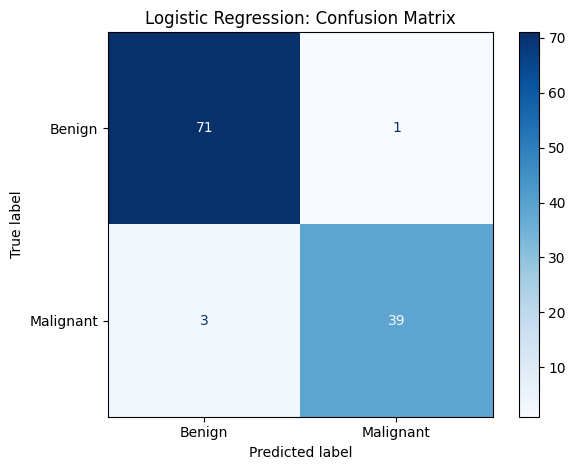

In [7]:
cm_lr = confusion_matrix(y_test, pred_lr, labels=[0, 1])
ConfusionMatrixDisplay(cm_lr, display_labels=["Benign", "Malignant"]).plot(
    cmap="Blues", values_format="d")
plt.title("Logistic Regression: Confusion Matrix")
plt.tight_layout()
plt.show()

## A7.3 — Figure 3: Random Forest confusion matrix

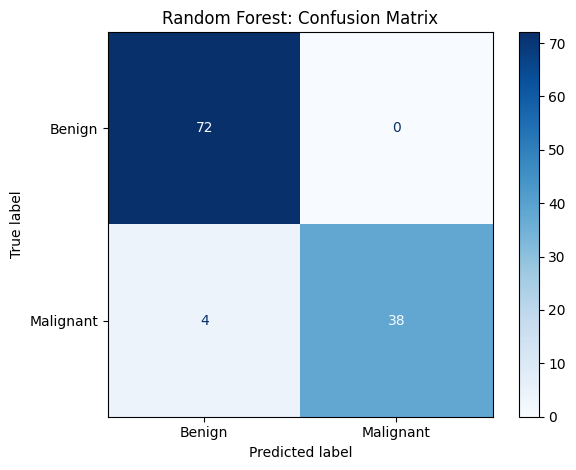

In [8]:
cm_rf = confusion_matrix(y_test, pred_rf, labels=[0, 1])
ConfusionMatrixDisplay(cm_rf, display_labels=["Benign", "Malignant"]).plot(
    cmap="Blues", values_format="d")
plt.title("Random Forest: Confusion Matrix")
plt.tight_layout()
plt.show()

## A7.4 — Naive benchmark (DummyClassifier)
Predicts the majority class for every case. Scores respectably on accuracy while detecting no malignancies.

In [9]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred_dummy = dummy.predict(X_test)
print("Dummy accuracy : %.3f" % accuracy_score(y_test, pred_dummy))
print("Dummy malignant recall: %.3f" % recall_score(y_test, pred_dummy, zero_division=0))

Dummy accuracy : 0.632
Dummy malignant recall: 0.000


## A7.5 — Confidence interval on held-out recall
Bootstrap 95% confidence interval on malignant recall for each model. Overlapping intervals show the two models are not separable on the metric that matters.

In [10]:
rng = np.random.default_rng(42)

def bootstrap_recall_ci(y_true, y_pred, n_boot=2000):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    idx = np.arange(len(y_true))
    vals = []
    for _ in range(n_boot):
        s = rng.choice(idx, size=len(idx), replace=True)
        if y_true[s].sum() == 0:
            continue
        vals.append(recall_score(y_true[s], y_pred[s], zero_division=0))
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return lo, hi

for name, pred in [("Logistic Regression", pred_lr), ("Random Forest", pred_rf)]:
    lo, hi = bootstrap_recall_ci(y_test, pred)
    print("%-20s recall %.3f  95%% CI [%.3f, %.3f]" %
          (name, recall_score(y_test, pred), lo, hi))

Logistic Regression  recall 0.929  95% CI [0.841, 1.000]


Random Forest        recall 0.905  95% CI [0.806, 0.979]


## A7.6 — McNemar's test on paired predictions
The standard test for two classifiers on the same test set. It compares only the cases where the models disagree. A high p-value means the disagreement is consistent with chance: no evidence either model is better.

In [11]:
lr_correct = (pred_lr == y_test)
rf_correct = (pred_rf == y_test)
b = int(np.sum(lr_correct & ~rf_correct))   # LR right, RF wrong
c = int(np.sum(~lr_correct & rf_correct))   # RF right, LR wrong
n_discordant = b + c

p_value = binomtest(b, n_discordant, 0.5).pvalue if n_discordant else 1.0
print("Discordant pairs: LR-only correct = %d, RF-only correct = %d" % (b, c))
print("McNemar exact p = %.3f" % p_value)

Discordant pairs: LR-only correct = 3, RF-only correct = 3
McNemar exact p = 1.000


## A7.7 — Cost-weighted comparison
The two models make the same number of accuracy errors but not the same kind. This weights each error type by a cost ratio R = cost(false negative) / cost(false positive) and reports the lower-cost model at several ratios.

In [12]:
fn_lr, fp_lr = 3, 1
fn_rf, fp_rf = 4, 0
print("R (FN:FP)   LR cost   RF cost   lower-cost")
for R in [1, 5, 10, 20]:
    cost_lr = fn_lr * R + fp_lr
    cost_rf = fn_rf * R + fp_rf
    lower = "LR" if cost_lr < cost_rf else ("RF" if cost_rf < cost_lr else "tie")
    print("%6d %10d %9d      %s" % (R, cost_lr, cost_rf, lower))
print("Break-even: LR cost (3R+1) < RF cost (4R) for all R > 1.")

R (FN:FP)   LR cost   RF cost   lower-cost
     1          4         4      tie
     5         16        20      LR
    10         31        40      LR
    20         61        80      LR
Break-even: LR cost (3R+1) < RF cost (4R) for all R > 1.


## A8.1 — Feature correlation (Table 5)
Radius, perimeter and area are related by construction, so their coefficients are individually unstable.

In [13]:
corr = df.corr()
mask = np.triu(np.ones(corr.shape), k=1).astype(bool)
pairs = corr.abs().where(mask).stack().sort_values(ascending=False)
for (a, b), v in pairs.head(5).items():
    print("r = %.3f %s <-> %s" % (v, a, b))
print("Pairs with |r| >= 0.90:", int((pairs >= 0.90).sum()))

r = 0.998 mean radius <-> mean perimeter
r = 0.994 worst radius <-> worst perimeter
r = 0.987 mean radius <-> mean area
r = 0.987 mean perimeter <-> mean area
r = 0.984 worst radius <-> worst area
Pairs with |r| >= 0.90: 21


## A8.2 — Threshold sensitivity (Appendix B, Table B1)
The operating point, not the algorithm, governs the error that carries the clinical cost.

In [14]:
proba = lr_pipe.predict_proba(X_test)[:, 1]
for t in [0.30, 0.40, 0.50]:
    p = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, p, labels=[0, 1]).ravel()
    print("threshold %.2f -> false negatives %d, false positives %d" % (t, fn, fp))

threshold 0.30 -> false negatives 1, false positives 1
threshold 0.40 -> false negatives 2, false positives 1
threshold 0.50 -> false negatives 3, false positives 1
